In [5]:
from google.colab import files

uploaded = files.upload()

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
df = pd.read_csv('retail_sales_dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,24-11-2023,CUST001,Male,34,Beauty,3,50,150
1,2,27-02-2023,CUST002,Female,26,Clothing,2,500,1000
2,3,13-01-2023,CUST003,Male,50,Electronics,1,30,30
3,4,21-05-2023,CUST004,Male,37,Clothing,1,500,500
4,5,06-05-2023,CUST005,Male,30,Beauty,2,50,100


In [10]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1000, 9)


In [12]:
print(df.columns)

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')


In [13]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [14]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [15]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")

Duplicates removed successfully!


In [16]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1000, 9)


In [17]:
total_revenue = df['Total Amount'].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 456000


In [18]:
average_sales = df['Total Amount'].mean()

print("Average Sales:", round(average_sales, 2))

Average Sales: 456.0


In [19]:
total_transactions = df['Transaction ID'].nunique()

print("Total Transactions:", total_transactions)

Total Transactions: 1000


In [20]:
total_quantity = df['Quantity'].sum()

print("Total Quantity Sold:", total_quantity)

Total Quantity Sold: 2514


In [21]:
category_sales = df.groupby('Product Category')['Total Amount'].sum()

print("Sales by Product Category:")
print(category_sales)

Sales by Product Category:
Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


In [22]:
print("RETAIL SALES ANALYSIS")
print("-----------------------------")
print("Total Revenue:", total_revenue)
print("Average Sales:", round(average_sales, 2))
print("Total Transactions:", total_transactions)
print("Total Quantity Sold:", total_quantity)
print("-----------------------------")
print("Category-wise Sales:")
print(category_sales)

RETAIL SALES ANALYSIS
-----------------------------
Total Revenue: 456000
Average Sales: 456.0
Total Transactions: 1000
Total Quantity Sold: 2514
-----------------------------
Category-wise Sales:
Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


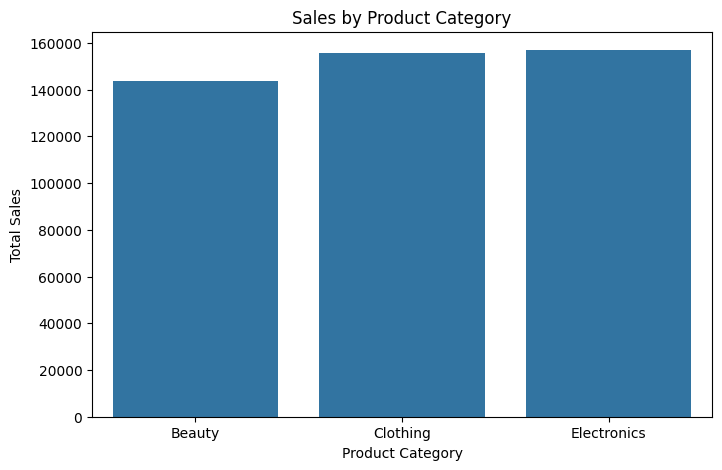

In [23]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.show()

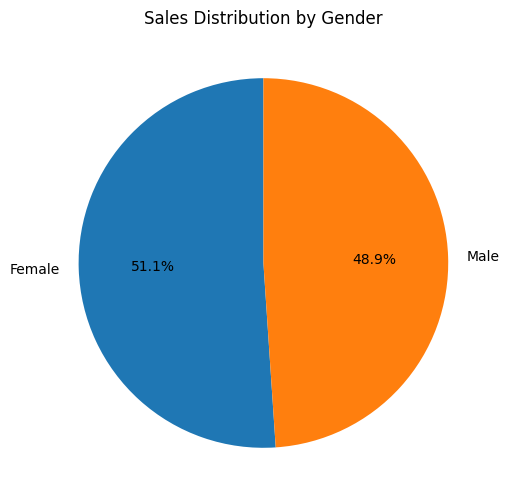

In [24]:
gender_sales = df.groupby('Gender')['Total Amount'].sum()

plt.figure(figsize=(6,6))

plt.pie(
    gender_sales,
    labels=gender_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Sales Distribution by Gender")
plt.show()

/tmp/ipykernel_1022/2279909187.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


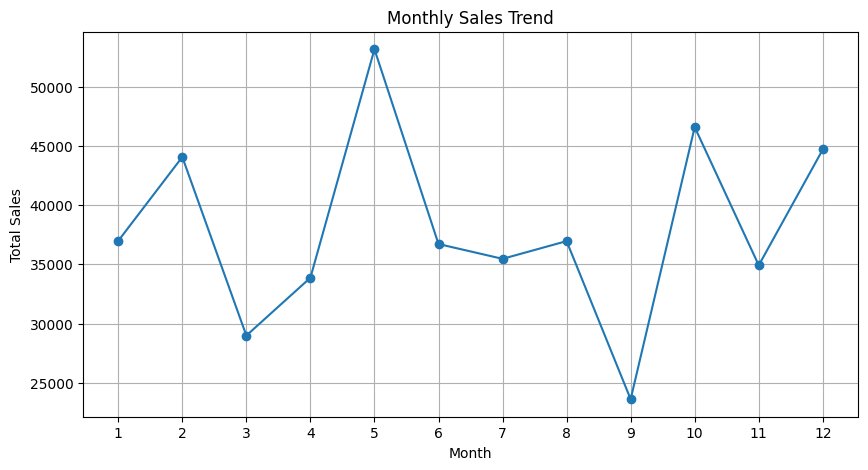

In [25]:
df['Date'] = pd.to_datetime(df['Date'])

df['Month'] = df['Date'].dt.month

monthly_sales = df.groupby('Month')['Total Amount'].sum()

plt.figure(figsize=(10,5))

plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1,13))
plt.grid(True)

plt.show()

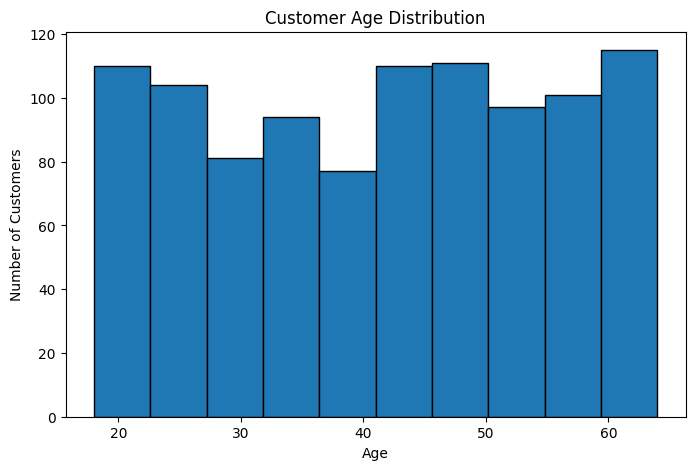

In [26]:
plt.figure(figsize=(8,5))

plt.hist(df['Age'], bins=10, edgecolor='black')

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

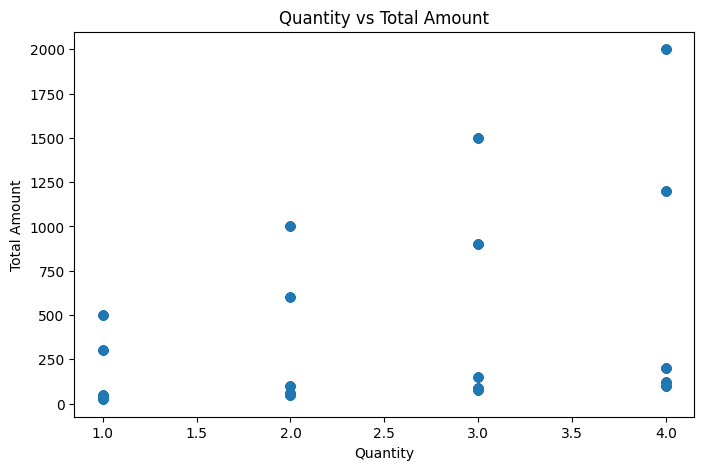

In [27]:
plt.figure(figsize=(8,5))

plt.scatter(df['Quantity'], df['Total Amount'])

plt.title("Quantity vs Total Amount")
plt.xlabel("Quantity")
plt.ylabel("Total Amount")

plt.show()

In [28]:
top_category = category_sales.idxmax()
top_sales = category_sales.max()

print("Top Selling Category:", top_category)
print("Revenue Generated:", top_sales)

Top Selling Category: Electronics
Revenue Generated: 156905


In [29]:
monthly_sales = df.groupby(df['Date'].dt.month_name())['Total Amount'].sum()

best_month = monthly_sales.idxmax()

print("Highest Sales Month:", best_month)
print("Highest Monthly Revenue:", monthly_sales.max())

Highest Sales Month: May
Highest Monthly Revenue: 53150


In [30]:
gender_sales = df.groupby('Gender')['Total Amount'].sum()

print("Sales by Gender:")
print(gender_sales)

print("Highest Spending Gender:", gender_sales.idxmax())

Sales by Gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64
Highest Spending Gender: Female


In [31]:
print("Average Customer Age:", round(df['Age'].mean(), 2))

print("Youngest Customer:", df['Age'].min())

print("Oldest Customer:", df['Age'].max())

Average Customer Age: 41.39
Youngest Customer: 18
Oldest Customer: 64


In [32]:
print("===== BUSINESS INSIGHTS =====")

print("1. Best Selling Category:", top_category)

print("2. Best Sales Month:", best_month)

print("3. Highest Spending Gender:", gender_sales.idxmax())

print("4. Average Customer Age:", round(df['Age'].mean(), 2))

print("5. Total Revenue:", total_revenue)

print("==============================")

===== BUSINESS INSIGHTS =====
1. Best Selling Category: Electronics
2. Best Sales Month: May
3. Highest Spending Gender: Female
4. Average Customer Age: 41.39
5. Total Revenue: 456000


In [33]:
import os

os.makedirs('/content/Graphs', exist_ok=True)

print("Graphs folder created successfully!")

Graphs folder created successfully!


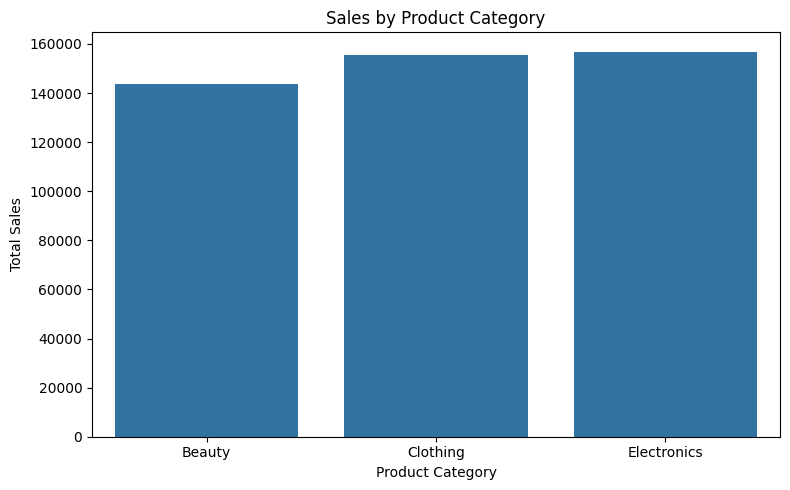

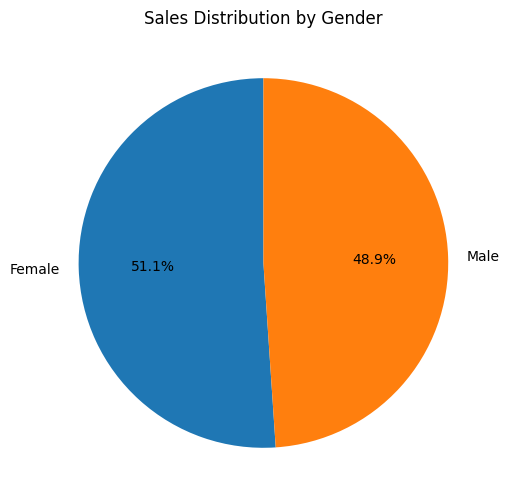

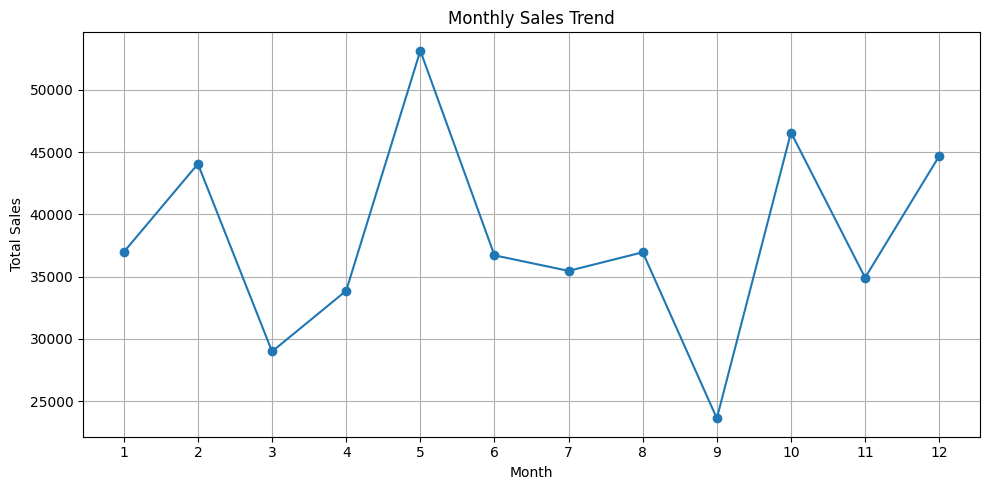

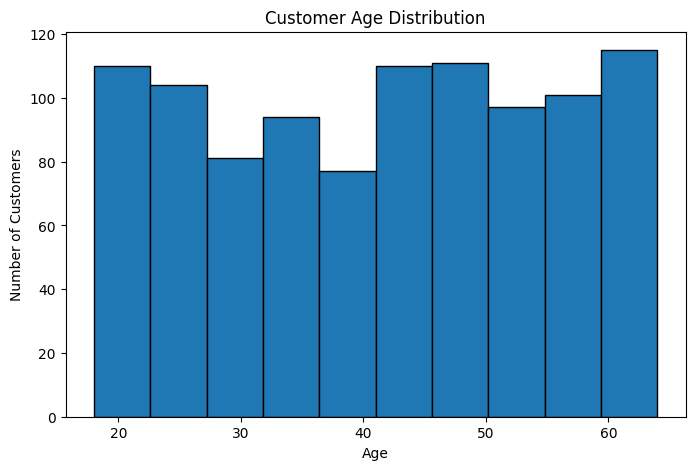

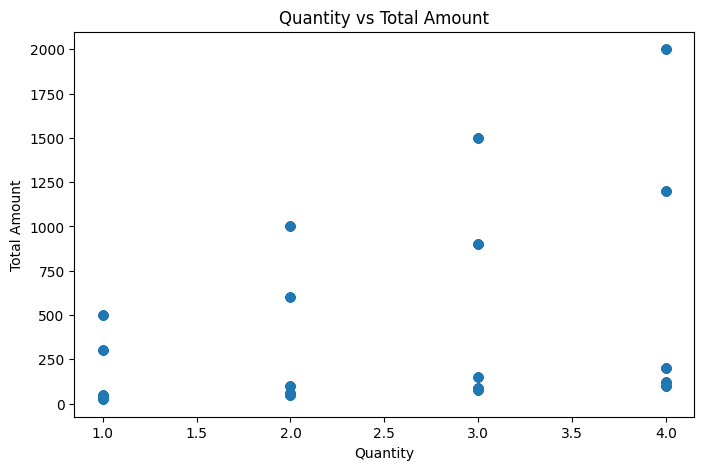

All five graphs saved successfully!


In [34]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

os.makedirs('/content/Graphs', exist_ok=True)

# 1. Product Category Sales
category_sales = df.groupby('Product Category')['Total Amount'].sum()

plt.figure(figsize=(8,5))
sns.barplot(x=category_sales.index, y=category_sales.values)
plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig('/content/Graphs/category_sales.png')
plt.show()
plt.close()

# 2. Gender Sales
gender_sales = df.groupby('Gender')['Total Amount'].sum()

plt.figure(figsize=(6,6))
plt.pie(gender_sales, labels=gender_sales.index,
        autopct='%1.1f%%', startangle=90)
plt.title("Sales Distribution by Gender")
plt.savefig('/content/Graphs/gender_sales.png')
plt.show()
plt.close()

# 3. Monthly Sales Trend
df['Date'] = pd.to_datetime(df['Date'])
monthly_sales = df.groupby(df['Date'].dt.month)['Total Amount'].sum()

plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1,13))
plt.grid(True)
plt.tight_layout()
plt.savefig('/content/Graphs/monthly_sales.png')
plt.show()
plt.close()

# 4. Customer Age Distribution
plt.figure(figsize=(8,5))
plt.hist(df['Age'], bins=10, edgecolor='black')
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.savefig('/content/Graphs/age_distribution.png')
plt.show()
plt.close()

# 5. Quantity vs Total Amount
plt.figure(figsize=(8,5))
plt.scatter(df['Quantity'], df['Total Amount'])
plt.title("Quantity vs Total Amount")
plt.xlabel("Quantity")
plt.ylabel("Total Amount")
plt.savefig('/content/Graphs/quantity_vs_amount.png')
plt.show()
plt.close()

print("All five graphs saved successfully!")

In [35]:
import shutil

shutil.make_archive(
    '/content/Retail_Graphs',
    'zip',
    '/content/Graphs'
)

from google.colab import files
files.download('/content/Retail_Graphs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>